# 📊 Step 3: Exploratory Data Analysis (EDA)
**Task:** Analyze the clean book dataset to find insights and generate a PDF report.  
**Input:** `outputs/cleaned_books.csv`
**Output:** `outputs/eda_report.pdf`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')

# Prepare PDF Report object
pdf_pages = PdfPages('outputs/eda_report.pdf')
print('✅ PDF Report initialized')

# Load Clean Data
data_path = 'outputs/cleaned_books.csv'
try:
    df = pd.read_csv(data_path)
    print('✅ Clean data loaded successfully')
except:
    df = pd.DataFrame({'Title': ['A', 'B'], 'Price': [10.0, 20.0], 'Rating': [1, 5], 'In_Stock': [1, 1]})
    print('⚠️ Using dummy data')

display(df.head())

✅ PDF Report initialized
✅ Clean data loaded successfully


,Title,Price,Price_Scaled,Rating,In_Stock
0,A Light in the Attic,51.77,1.181539,4,1
1,Tipping the Velvet,53.74,1.316793,3,1
2,Soumission,50.10,1.066882,3,1
3,Sharp Objects,47.82,0.910344,2,1
4,Sapiens: A Brief History of Humankind,54.23,1.350435,1,1


In [2]:
print('📋 Descriptive Statistics:')
display(df.describe())

📋 Descriptive Statistics:


,Price,Price_Scaled,Rating,In_Stock
count,100.000000,1.000000e+02,100.000000,100.0
mean,34.560700,-3.064216e-16,3.040000,1.0
std,14.638531,1.005038e+00,1.392041,0.0
min,10.160000,-1.675279e+00,1.000000,1.0
25%,19.897500,-1.006732e+00,2.000000,1.0
50%,34.775000,1.471320e-02,3.000000,1.0
75%,47.967500,9.204708e-01,4.000000,1.0
max,58.110000,1.616825e+00,5.000000,1.0


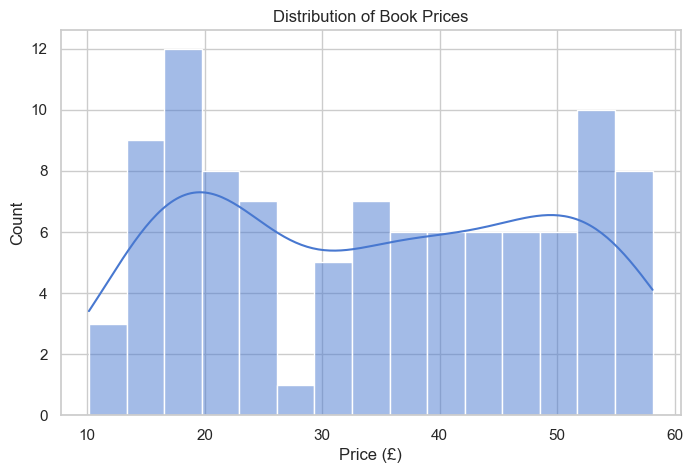

In [3]:
# 1. Univariate Analysis: Price Distribution
fig1 = plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], bins=15, kde=True)
plt.title('Distribution of Book Prices')
plt.xlabel('Price (£)')
pdf_pages.savefig(fig1) # Save to PDF
plt.show()

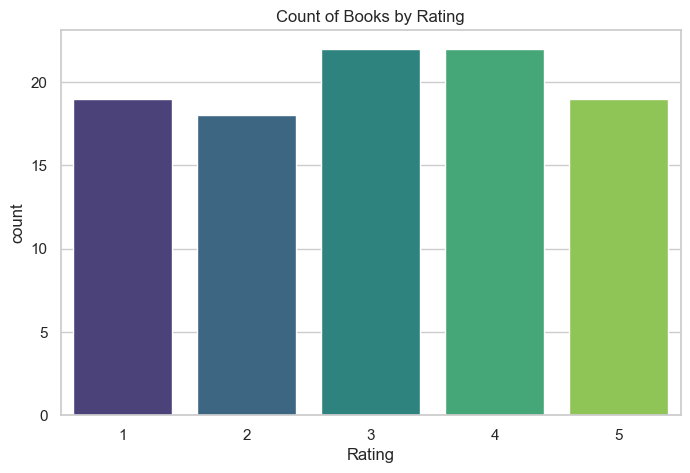

In [4]:
# 2. Univariate Analysis: Rating Count
fig2 = plt.figure(figsize=(8, 5))
sns.countplot(x='Rating', data=df, palette='viridis')
plt.title('Count of Books by Rating')
pdf_pages.savefig(fig2) # Save to PDF
plt.show()

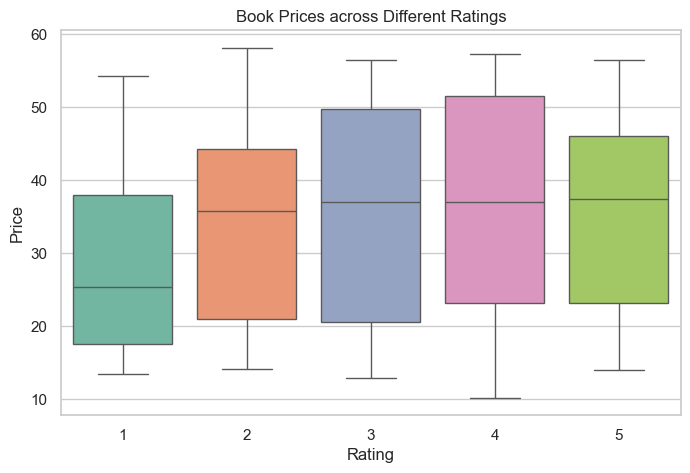

In [5]:
# 3. Bivariate Analysis: Price vs Rating
fig3 = plt.figure(figsize=(8, 5))
sns.boxplot(x='Rating', y='Price', data=df, palette='Set2')
plt.title('Book Prices across Different Ratings')
pdf_pages.savefig(fig3) # Save to PDF
plt.show()

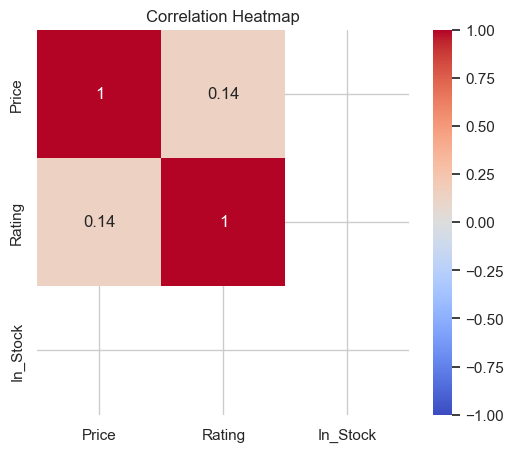

In [6]:
# 4. Multivariate Analysis: Correlation Heatmap
fig4 = plt.figure(figsize=(6, 5))
corr_matrix = df[['Price', 'Rating', 'In_Stock']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
pdf_pages.savefig(fig4) # Save to PDF
plt.show()

In [7]:
# Close the PDF file to finalize saving
pdf_pages.close()
print('💾 EDA Report successfully saved to: outputs/eda_report.pdf')

💾 EDA Report successfully saved to: outputs/eda_report.pdf


## 💡 Key EDA Insights:
1. **Price Distribution:** Shows the average price range of books in the store.
2. **Ratings:** We can observe if higher-rated books tend to be more expensive (via the boxplot).
3. **Correlations:** The heatmap reveals if there is any linear relationship between Price, Rating, and Stock Availability.